# DSC 670 – Milestone 3: Fine-Tuning a Tennis Scouting-Report Model

**Project:** Generative AI-driven player scouting and style profiling for professional tennis
**Student:** Gerardo
**Model fine-tuned:** an open model from Hugging Face (set in the config cell), **full fine-tuning** of all weights (no LoRA), run on a Google Colab GPU

**Why Hugging Face instead of OpenAI.** OpenAI's fine-tuning is no longer available to new API organizations, so, as approved by the professor, this milestone fine-tunes a Hugging Face model in Colab instead. No API key or paid account is needed: the model used is public and downloads without logging in.

**How this notebook is organized**

1. Setup (Colab GPU) and configuration
2. Data: build one statistical profile per player per surface from the Match Charting Project
3. Labels: a transparent rule-based style archetype for each profile
4. Stat cards: the text the model reads
5. Training targets: scouting reports written by a transparent rule-based writer
6. Train / validation / test split and JSONL files
7. Scoring functions for generated reports
8. Baseline: the base model *before* fine-tuning
9. Prepare the training data (tokenization and loss masking)
10. Fine-tune and track the run
11. Training metrics
12. Evaluation on held-out players: base vs. fine-tuned
13. Conclusions

**Data attribution.** Shot-by-shot data comes from *The Tennis Abstract Match Charting Project* (Jeff Sackmann and volunteer charters), licensed CC BY-NC-SA 4.0 (attribution required, non-commercial use). Source: https://github.com/JeffSackmann/tennis_MatchChartingProject

## 1. Setup and configuration

In [1]:
%pip install -q transformers accelerate pandas matplotlib

In [2]:
import io, os, re, json, time, random, gc, urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# ---- Model --------------------------------------------------------------
# A small, public (ungated) instruction-tuned model: no Hugging Face login or API key needed.
# ~0.5B parameters, so a FULL fine-tune (every weight updated) fits on a free Colab T4 GPU.
MODEL_NAME = "Qwen/Qwen2.5-0.5B-Instruct"

# ---- Fine-tuning settings -----------------------------------------------
N_EPOCHS = 3
LEARNING_RATE = 3e-5
BATCH_SIZE = 1            # per-step batch; kept at 1 so a T4 does not run out of memory
GRAD_ACCUM = 8            # effective batch size = BATCH_SIZE x GRAD_ACCUM
MAX_SEQ_LEN = 2048
MAX_NEW_TOKENS = 600      # length limit for generated reports (must exceed the longest report; digits cost one token each)
GEN_BATCH_SIZE = 8

# ---- Data settings ------------------------------------------------------
MIN_DATE = 20100101       # only matches since 2010, so styles are not compared across very different eras
MIN_MATCHES = 5           # minimum charted matches for a player on a surface to get a profile

DATA_DIR, OUT_DIR = Path("tennis_data"), Path("outputs")
DATA_DIR.mkdir(exist_ok=True)
OUT_DIR.mkdir(exist_ok=True)

ARCHETYPES = ["aggressive baseliner", "counterpuncher", "all-court player",
              "serve-plus-one attacker", "defensive specialist"]

In [3]:
if not torch.cuda.is_available():
    raise SystemExit("No GPU found. In Colab: Runtime > Change runtime type > T4 GPU, then reconnect and run again.")

gpu_name = torch.cuda.get_device_name(0)
gpu_mem_gb = torch.cuda.get_device_properties(0).total_memory / 1e9
USE_BF16 = torch.cuda.get_device_capability(0)[0] >= 8   # T4 (compute capability 7.5) uses fp16 instead
print(f"GPU: {gpu_name} | memory: {gpu_mem_gb:.1f} GB | mixed precision: {'bf16' if USE_BF16 else 'fp16'}")
import transformers
print("transformers", transformers.__version__, "| torch", torch.__version__)

GPU: Tesla T4 | memory: 15.6 GB | mixed precision: fp16
transformers 5.21.0 | torch 2.11.0+cu130


## 2. Data: player-by-surface statistical profiles

In [4]:
BASE = "https://raw.githubusercontent.com/JeffSackmann/tennis_MatchChartingProject/master/"
FILES = ["charting-m-matches", "charting-m-stats-Overview", "charting-m-stats-Rally",
         "charting-m-stats-NetPoints", "charting-m-stats-ServeDirection", "charting-m-stats-ShotDirection"]

for f in FILES:
    path = DATA_DIR / f"{f}.csv"
    if not path.exists():
        urllib.request.urlretrieve(BASE + f + ".csv", path)
    print(f"{f:36s} {path.stat().st_size/1e6:6.1f} MB")

charting-m-matches                      1.1 MB
charting-m-stats-Overview               6.7 MB
charting-m-stats-Rally                 11.0 MB
charting-m-stats-NetPoints              6.2 MB
charting-m-stats-ServeDirection         4.7 MB
charting-m-stats-ShotDirection          5.3 MB


In [5]:
def dedupe(df, keys):
    # The charting data occasionally contains the same match charted twice; keep one copy.
    return df.drop_duplicates(keys, keep="first")

# --- which matches qualify -------------------------------------------------
matches = pd.read_csv(DATA_DIR / "charting-m-matches.csv")
matches = matches[pd.to_numeric(matches["Date"], errors="coerce").notna()].copy()
matches["Date"] = matches["Date"].astype(int)
matches = matches[(matches["Date"] >= MIN_DATE) & matches["Surface"].isin(["Hard", "Clay", "Grass"])]
surface_of = matches.drop_duplicates("match_id").set_index("match_id")["Surface"]
keep = set(surface_of.index)
print("qualifying charted matches:", len(keep))

# --- serve / return / winners / errors per player per match ----------------
ov = pd.read_csv(DATA_DIR / "charting-m-stats-Overview.csv")
ov = dedupe(ov[(ov["set"] == "Total") & ov["match_id"].isin(keep)], ["match_id", "player"])
ov["surface"] = ov["match_id"].map(surface_of)

# --- rally length: plain buckets cover every point in the match -------------
ra = pd.read_csv(DATA_DIR / "charting-m-stats-Rally.csv")
ra = ra[ra["row"].isin(["1-3", "4-6", "7-9", "10"]) & ra["match_id"].isin(keep)]
ra = dedupe(ra, ["match_id", "server", "row"])
side1 = ra.assign(player=ra["server"], won=ra["pl1_won"])      # pl1 is the player named in 'server'
side2 = ra.assign(player=ra["returner"], won=ra["pl2_won"])    # pl2 is the player named in 'returner'
rl = pd.concat([side1, side2])[["match_id", "player", "row", "pts", "won"]]
rl["b"] = rl["row"].map({"1-3": "r13", "4-6": "r46", "7-9": "r79", "10": "r10"})
rl = rl.pivot_table(index=["match_id", "player"], columns="b", values=["pts", "won"],
                    aggfunc="sum", fill_value=0)
rl.columns = [f"{a}_{b}" for a, b in rl.columns]
rl = rl.reset_index()

# --- net play, serve placement, groundstroke direction ----------------------
nt = pd.read_csv(DATA_DIR / "charting-m-stats-NetPoints.csv")
nt = dedupe(nt[(nt["row"] == "NetPoints") & nt["match_id"].isin(keep)], ["match_id", "player"])
nt = nt[["match_id", "player", "net_pts", "pts_won"]].rename(columns={"pts_won": "net_won"})

sd = pd.read_csv(DATA_DIR / "charting-m-stats-ServeDirection.csv")
sd = dedupe(sd[(sd["row"] == "Total") & sd["match_id"].isin(keep)], ["match_id", "player"])
sd = sd[["match_id", "player", "deuce_wide", "deuce_middle", "deuce_t", "ad_wide", "ad_middle", "ad_t"]]

sh = pd.read_csv(DATA_DIR / "charting-m-stats-ShotDirection.csv")
sh = sh[sh["match_id"].isin(keep)]
fh = dedupe(sh[sh["row"] == "F"], ["match_id", "player"]).copy()
fh["fh_tot"] = fh[["crosscourt", "down_middle", "down_the_line", "inside_out", "inside_in"]].sum(axis=1)
fh = fh[["match_id", "player", "inside_out", "inside_in", "fh_tot"]].rename(
    columns={"inside_out": "fh_io", "inside_in": "fh_ii"})
bh = dedupe(sh[sh["row"] == "B"], ["match_id", "player"]).copy()
bh["bh_tot"] = bh[["crosscourt", "down_middle", "down_the_line"]].sum(axis=1)
bh = bh[["match_id", "player", "down_the_line", "bh_tot"]].rename(columns={"down_the_line": "bh_dtl"})

# --- one row per player per match, then aggregate to player x surface -------
pm = (ov.merge(rl, on=["match_id", "player"]).merge(nt, on=["match_id", "player"])
        .merge(sd, on=["match_id", "player"]).merge(fh, on=["match_id", "player"])
        .merge(bh, on=["match_id", "player"]))
print(f"player-match rows: overview {len(ov)} -> after joining all tables {len(pm)}")

sum_cols = [c for c in pm.columns if c not in ("match_id", "player", "set", "surface")]
grp = pm.groupby(["player", "surface"])
units = grp[sum_cols].sum()
units["matches"] = grp.size()
units = units[units["matches"] >= MIN_MATCHES].reset_index()
print(f"player-surface profiles with >= {MIN_MATCHES} charted matches: {len(units)} "
      f"({units['player'].nunique()} players)")
print(units["surface"].value_counts().to_string())

qualifying charted matches: 5598
player-match rows: overview 11164 -> after joining all tables 11021
player-surface profiles with >= 5 charted matches: 407 (237 players)
surface
Hard     213
Clay     139
Grass     55


In [6]:
u = units.copy()
pct = lambda a, b: 100 * a / b

# serve
u["ace_rate"] = pct(u["aces"], u["serve_pts"])
u["df_rate"] = pct(u["dfs"], u["serve_pts"])
u["first_in_pct"] = pct(u["first_in"], u["serve_pts"])
u["first_won_pct"] = pct(u["first_won"], u["first_in"])
u["second_won_pct"] = pct(u["second_won"], u["serve_pts"] - u["first_in"])   # second serves include double faults
u["bp_saved_pct"] = pct(u["bp_saved"], u["bk_pts"])
# return
u["return_won_pct"] = pct(u["return_pts_won"], u["return_pts"])
# point construction
u["pts_total"] = u["serve_pts"] + u["return_pts"]
u["winners_per100"] = pct(u["winners"], u["pts_total"])
u["ue_per100"] = pct(u["unforced"], u["pts_total"])
u["winner_ue_ratio"] = u["winners"] / u["unforced"]
# rally length
rally_total = u["pts_r13"] + u["pts_r46"] + u["pts_r79"] + u["pts_r10"]
u["rally_1_3"] = pct(u["pts_r13"], rally_total)
u["rally_4_6"] = pct(u["pts_r46"], rally_total)
u["rally_7_9"] = pct(u["pts_r79"], rally_total)
u["rally_10plus"] = pct(u["pts_r10"], rally_total)
u["long_rally_share"] = u["rally_7_9"] + u["rally_10plus"]
u["long_rally_win_pct"] = pct(u["won_r79"] + u["won_r10"], u["pts_r79"] + u["pts_r10"])
# net play
u["net_per100"] = pct(u["net_pts"], u["pts_total"])
u["net_win_pct"] = pct(u["net_won"], u["net_pts"])
# serve placement (deuce / ad court)
d_all = u["deuce_wide"] + u["deuce_middle"] + u["deuce_t"]
a_all = u["ad_wide"] + u["ad_middle"] + u["ad_t"]
for side, tot in (("deuce", d_all), ("ad", a_all)):
    u[f"{side}_wide_pct"] = pct(u[f"{side}_wide"], tot)
    u[f"{side}_body_pct"] = pct(u[f"{side}_middle"], tot)
    u[f"{side}_t_pct"] = pct(u[f"{side}_t"], tot)
# groundstroke direction
u["fh_inside_pct"] = pct(u["fh_io"] + u["fh_ii"], u["fh_tot"])
u["bh_dtl_pct"] = pct(u["bh_dtl"], u["bh_tot"])

feature_cols = ["ace_rate", "df_rate", "first_in_pct", "first_won_pct", "second_won_pct", "bp_saved_pct",
                "return_won_pct", "winners_per100", "ue_per100", "winner_ue_ratio",
                "rally_1_3", "rally_4_6", "rally_7_9", "rally_10plus", "long_rally_share", "long_rally_win_pct",
                "net_per100", "net_win_pct", "deuce_wide_pct", "deuce_body_pct", "deuce_t_pct",
                "ad_wide_pct", "ad_body_pct", "ad_t_pct", "fh_inside_pct", "bh_dtl_pct"]
before = len(u)
u = u.replace([np.inf, -np.inf], np.nan).dropna(subset=feature_cols).reset_index(drop=True)
print(f"dropped {before - len(u)} profiles with undefined stats; {len(u)} remain")
u[feature_cols].describe().T[["mean", "std", "min", "max"]].round(1)

dropped 0 profiles with undefined stats; 407 remain


,mean,std,min,max
ace_rate,7.8,4.4,0.5,23.9
df_rate,3.5,1.4,0.2,10.4
first_in_pct,62.2,4.0,50.4,72.8
first_won_pct,70.8,5.1,54.6,81.6
second_won_pct,49.9,4.1,28.8,60.4
bp_saved_pct,60.5,6.8,38.3,79.5
return_won_pct,34.7,4.0,21.6,45.3
winners_per100,16.9,3.3,10.3,30.1
ue_per100,18.3,2.9,11.0,27.8
winner_ue_ratio,0.9,0.2,0.5,1.9


## 3. Style archetype labels (rule-based, transparent)

The training reports need a consistent style label. Instead of asking a model to guess a label (which would make the "label accuracy" metric circular), each profile gets an archetype from explicit rules: every profile is ranked by percentile (among profiles on the same surface) on a few statistics, each archetype gets a score from the percentiles that describe it, the scores are standardized, and the highest score is the primary archetype and the second highest the secondary.

This is a heuristic, not tennis ground truth. It gives the project one fixed, repeatable definition of the five archetypes from the Milestone 1/2 taxonomy.

In [7]:
pctl_cols = ["ace_rate", "first_won_pct", "return_won_pct", "winners_per100", "ue_per100", "winner_ue_ratio",
             "rally_1_3", "long_rally_share", "net_per100", "net_win_pct", "bp_saved_pct", "second_won_pct", "df_rate", "long_rally_win_pct"]
# Percentiles are computed within each surface, so "high" means high relative to peers on the same surface
# (grass serving numbers are not compared with clay rally lengths).
for c in pctl_cols:
    u[f"p_{c}"] = 100 * u.groupby("surface")[c].rank(pct=True)
inv = lambda s: 100 - s

score = pd.DataFrame({
    "serve-plus-one attacker": (u["p_ace_rate"] + u["p_first_won_pct"] + u["p_rally_1_3"]) / 3,
    "aggressive baseliner":    (u["p_winners_per100"] + u["p_ue_per100"] + inv(u["p_net_per100"])) / 3,
    "counterpuncher":          (u["p_return_won_pct"] + inv(u["p_ue_per100"]) + u["p_long_rally_share"]) / 3,
    "all-court player":        (u["p_net_per100"] + u["p_net_win_pct"] + u["p_winner_ue_ratio"]) / 3,
    "defensive specialist":    (u["p_long_rally_share"] + inv(u["p_winners_per100"]) + inv(u["p_first_won_pct"])) / 3,
})
# Standardize each archetype's score so that no archetype wins just because its score is naturally more spread out.
score = (score - score.mean()) / score.std()
ranked = score.apply(lambda r: r.sort_values(ascending=False).index.tolist(), axis=1)
u["primary"] = ranked.str[0]
u["secondary"] = ranked.str[1]

print("primary archetype counts:")
print(u["primary"].value_counts().to_string())
print("\nprimary archetype by surface:")
print(pd.crosstab(u["surface"], u["primary"]).to_string())
print("\nexamples:")
print(u[["player", "surface", "matches", "primary", "secondary"]].sample(8, random_state=SEED).to_string(index=False))

primary archetype counts:
primary
defensive specialist       99
aggressive baseliner       89
counterpuncher             76
all-court player           72
serve-plus-one attacker    71

primary archetype by surface:
primary  aggressive baseliner  all-court player  counterpuncher  defensive specialist  serve-plus-one attacker
surface                                                                                                       
Clay                       31                25              24                    31                       28
Grass                      12                 9              13                    13                        8
Hard                       46                38              39                    55                       35

examples:
               player surface  matches                 primary               secondary
       Carlos Alcaraz    Hard      127        all-court player          counterpuncher
Juan Martin Del Potro    Clay       23       

####Row Representation & Granularity Choice:Each row represents a single player-by-surface profile aggregated across all qualifying charted matches (minimum 5 matches) since 2010. Evaluating tennis players at the match level introduces high variance due to single-day opponent matchups, tactical adjustments, or physical conditions. Conversely, evaluating a player globally across all surfaces washes out surface-specific tactical identities. Aggregating by (player, surface) captures distinct play styles (e.g., Nadal on clay vs. grass) while providing a robust, multi-match sample size.   Archetype Balance & Distribution:The 407 qualifying profiles are distributed across the five archetypes as follows:Defensive Specialist: 99 (24.3%)   Aggressive Baseliner: 89 (21.9%)   Counterpuncher: 76 (18.7%)   All-Court Player: 72 (17.7%)   Serve-Plus-One Attacker: 71 (17.4%)   The distribution is well-balanced across all five classes, with no single archetype dominating excessively and no extreme minority class (each represents 17% to 25% of the data). This prevents class-imbalance collapse or bias toward a majority archetype during causal language modeling. Furthermore, calculating rank percentiles within each surface prevents surface biases (such as grass serve speed distorting clay rally baselines).   Tennis Domain Assessment of Sample Labels:Looking at the sampled outputs:Agreed Labels: Carlos Alcaraz on Hard labeled as All-Court Player (primary) with Counterpuncher (secondary) matches his high net-frequency and transition versatility. Andrey Rublev on Clay classified as Aggressive Baseliner (primary) and Serve-Plus-One Attacker (secondary) aligns with his baseline-heavy game. Marc-Andrea Huesler on Hard labeled as Serve-Plus-One Attacker is tactically spot-on for a big-serving left-hander.   Questionable Labels: Juan Martín del Potro on Clay labeled as Counterpuncher (primary) with Serve-Plus-One Attacker (secondary). Del Potro’s forehand and serve are offensive weapons rather than defensive tools. Because clay slows ball velocity, extends rallies, and depresses direct winner ratios, the heuristic over-indexed on his clay rally length share and misattributed counterpunching tendencies.   Weaknesses of Rule-Based Labels:Selection/Opponent Bias: The Match Charting Project disproportionately charts deep tournament rounds (quarterfinals through finals) featuring top-10 opponents, making players appear more defensive or error-prone than their average tour performance.Era and Sample Effects: Players with only 5 to 8 charted matches against elite competition skew percentiles compared to veterans with 50+ charted matches.   Rigid Threshold Weighting: Equal 3-metric averaging ignores how specific extreme weapons (e.g., John Isner's serve) dictate style regardless of rally metrics.   

## 4. Statistical profile text ("stat card") for each player

The model never sees the raw table. It sees a fixed-format text profile, which is what a user of the final app would paste in or generate from the data. The archetype labels are **not** in the profile; the model has to infer them.

In [8]:
def ordinal(n):
    n = int(round(n))
    return f"{n}{'th' if 10 <= n % 100 <= 20 else {1:'st',2:'nd',3:'rd'}.get(n % 10, 'th')}"

n_surface = u.groupby("surface").size()

def build_stat_card(r):
    return (
        f"PLAYER: {r['player']}\n"
        f"SURFACE: {r['surface']} (based on {int(r['matches'])} charted matches since {MIN_DATE // 10000})\n"
        f"SERVE: aces on {r['ace_rate']:.1f}% of serve points; double faults {r['df_rate']:.1f}%; "
        f"first serve in {r['first_in_pct']:.1f}%; first-serve points won {r['first_won_pct']:.1f}%; "
        f"second-serve points won {r['second_won_pct']:.1f}%; break points saved {r['bp_saved_pct']:.1f}%\n"
        f"SERVE PLACEMENT: deuce court wide {r['deuce_wide_pct']:.0f}% / body {r['deuce_body_pct']:.0f}% / T {r['deuce_t_pct']:.0f}%; "
        f"ad court wide {r['ad_wide_pct']:.0f}% / body {r['ad_body_pct']:.0f}% / T {r['ad_t_pct']:.0f}%\n"
        f"RETURN: return points won {r['return_won_pct']:.1f}%\n"
        f"POINT CONSTRUCTION: winners per 100 points {r['winners_per100']:.1f}; unforced errors per 100 points {r['ue_per100']:.1f}; "
        f"winner-to-error ratio {r['winner_ue_ratio']:.2f}\n"
        f"RALLY LENGTH: points ending within 1-3 shots {r['rally_1_3']:.0f}%, 4-6 shots {r['rally_4_6']:.0f}%, "
        f"7-9 shots {r['rally_7_9']:.0f}%, 10+ shots {r['rally_10plus']:.0f}%; "
        f"points won in rallies of 7+ shots {r['long_rally_win_pct']:.1f}%\n"
        f"NET PLAY: net points per 100 points {r['net_per100']:.1f}; net points won {r['net_win_pct']:.1f}%\n"
        f"GROUNDSTROKES: forehands hit inside-out or inside-in {r['fh_inside_pct']:.0f}%; backhands hit down the line {r['bh_dtl_pct']:.0f}%\n"
        f"RANK AMONG THE {n_surface[r['surface']]} {r['surface'].upper()}-SURFACE PROFILES IN THIS DATASET (percentile of the raw value; 100th = highest value): "
        f"aces {ordinal(r['p_ace_rate'])}; double faults {ordinal(r['p_df_rate'])}; "
        f"first-serve points won {ordinal(r['p_first_won_pct'])}; second-serve points won {ordinal(r['p_second_won_pct'])}; "
        f"break points saved {ordinal(r['p_bp_saved_pct'])}; return points won {ordinal(r['p_return_won_pct'])}; "
        f"winners {ordinal(r['p_winners_per100'])}; unforced errors {ordinal(r['p_ue_per100'])}; "
        f"winner-to-error ratio {ordinal(r['p_winner_ue_ratio'])}; points ending within 3 shots {ordinal(r['p_rally_1_3'])}; "
        f"long rallies (7+ shots) {ordinal(r['p_long_rally_share'])}; points won in long rallies {ordinal(r['p_long_rally_win_pct'])}; "
        f"net approaches {ordinal(r['p_net_per100'])}; net points won {ordinal(r['p_net_win_pct'])}"
    )

u["card"] = u.apply(build_stat_card, axis=1)
u["key"] = u["player"] + " | " + u["surface"]
print(u["card"].iloc[0])

PLAYER: Adrian Mannarino
SURFACE: Grass (based on 14 charted matches since 2010)
SERVE: aces on 5.1% of serve points; double faults 3.6%; first serve in 62.4%; first-serve points won 67.6%; second-serve points won 53.0%; break points saved 67.2%
SERVE PLACEMENT: deuce court wide 30% / body 28% / T 42%; ad court wide 65% / body 15% / T 19%
RETURN: return points won 32.9%
POINT CONSTRUCTION: winners per 100 points 14.4; unforced errors per 100 points 19.3; winner-to-error ratio 0.74
RALLY LENGTH: points ending within 1-3 shots 58%, 4-6 shots 21%, 7-9 shots 11%, 10+ shots 10%; points won in rallies of 7+ shots 54.0%
NET PLAY: net points per 100 points 15.4; net points won 72.0%
GROUNDSTROKES: forehands hit inside-out or inside-in 11%; backhands hit down the line 11%
RANK AMONG THE 55 GRASS-SURFACE PROFILES IN THIS DATASET (percentile of the raw value; 100th = highest value): aces 13th; double faults 56th; first-serve points won 7th; second-serve points won 44th; break points saved 62nd; r

## 5. Training targets: scouting reports

The model needs example **inputs** (the stat card) and **outputs** (a scouting report). There is no public collection of coach-written reports paired with these statistics, so the reports are generated by a transparent, rule-based writer:

1. Each profile's statistics are ranked by how strong or weak they are relative to other players on the same surface.
2. The three strongest and three weakest statistics become the Strengths and Weaknesses bullets, quoting the exact numbers from the profile.
3. The Game Plan combines a tactic for the primary archetype with tactics aimed at the player's weakest areas and at neutralizing the biggest strength.

This keeps the whole project free of paid API keys and makes every number checkable. The trade-off is that the target prose is template-like. The fine-tuned model is learning to *read the statistics, choose the right strengths and weaknesses, pick the archetype, and write in this format* rather than learning rich prose. A natural upgrade for later is to have a stronger language model rewrite the targets in more natural language (for example via Gemini or OpenAI chat calls, which are not affected by the fine-tuning restrictions).

In [9]:
REPORT_SECTIONS = ["PRIMARY ARCHETYPE:", "SECONDARY ARCHETYPE:", "PROFILE SUMMARY:",
                   "STRENGTHS:", "WEAKNESSES:", "GAME PLAN FOR THE OPPONENT:"]

# Long instruction prompt: used for the BASE-model baseline (the model has not been trained on the format).
SYSTEM_LONG = '''You are a professional tennis scouting analyst writing for coaches.
You receive a statistical profile of one player on one surface, built from charted professional matches.
Write a scouting report in EXACTLY this format and nothing else:

PRIMARY ARCHETYPE: <one of: aggressive baseliner | counterpuncher | all-court player | serve-plus-one attacker | defensive specialist>
SECONDARY ARCHETYPE: <a different one from the same list>
PROFILE SUMMARY: <2 sentences on how this player typically wins points>
STRENGTHS:
- <three bullets, each quoting a statistic from the profile>
WEAKNESSES:
- <three bullets, each quoting a statistic from the profile>
GAME PLAN FOR THE OPPONENT:
- <three concrete tactical bullets for a coach preparing to play this player>

Archetype definitions:
- aggressive baseliner: high winner and error counts, short-to-medium rallies, rarely at the net.
- counterpuncher: wins many return points, low error rate, comfortable absorbing pace in longer rallies.
- all-court player: mixes baseline play with frequent and successful net approaches.
- serve-plus-one attacker: wins quickly behind the serve and first strike; many points end within 3 shots.
- defensive specialist: relies on retrieving; long rallies, few winners, limited serve weapon.

Rules: quote numbers exactly as written in the profile; never use a number that is not in the profile;
do not use outside knowledge about the player (career, ranking, titles); do not invent statistics.'''

# Short prompt: used for the FINE-TUNED model (the format and style are learned from the training examples).
SYSTEM_SHORT = "You are a tennis scouting analyst. Write a coach-ready scouting report from the player profile in the standard format."

In [10]:
# Statistics the report writer can talk about. {v} is replaced by the number formatted EXACTLY as in the stat card.
METRICS = [
    dict(key="ace_rate", pcol="p_ace_rate", good_high=True, fmt=lambda r: f"{r['ace_rate']:.1f}%",
         S="Free points on serve: aces on {v} of serve points",
         W="Few free points on serve: aces on only {v} of serve points",
         plan_weak="Return aggressively and make the player earn every service point in rallies.",
         plan_strong="Stand closer on the return and block the serve deep to take away the ace threat."),
    dict(key="first_won_pct", pcol="p_first_won_pct", good_high=True, fmt=lambda r: f"{r['first_won_pct']:.1f}%",
         S="Dominant first serve: wins {v} of first-serve points",
         W="Vulnerable first serve: wins only {v} of first-serve points",
         plan_weak="Take first-serve returns early and aim for depth to turn first-serve points into neutral rallies.",
         plan_strong="Return deep through the middle on first serves to reduce the angles and survive the first strike."),
    dict(key="second_won_pct", pcol="p_second_won_pct", good_high=True, fmt=lambda r: f"{r['second_won_pct']:.1f}%",
         S="Reliable second serve: wins {v} of second-serve points",
         W="Weak second serve: wins only {v} of second-serve points",
         plan_weak="Move forward on second-serve returns and attack with a deep, aggressive first strike.",
         plan_strong="Do not expect cheap points off the second serve; return deep and build the point patiently."),
    dict(key="return_won_pct", pcol="p_return_won_pct", good_high=True, fmt=lambda r: f"{r['return_won_pct']:.1f}%",
         S="Strong returner: wins {v} of return points",
         W="Limited return game: wins only {v} of return points",
         plan_weak="Hold serve with confidence; the player rarely breaks, so protect your own service games and play freely.",
         plan_strong="Prioritize first-serve percentage and placement so the return cannot set the tone of the point."),
    dict(key="bp_saved_pct", pcol="p_bp_saved_pct", good_high=True, fmt=lambda r: f"{r['bp_saved_pct']:.1f}%",
         S="Composed under pressure: saves {v} of break points",
         W="Fragile under pressure: saves only {v} of break points",
         plan_weak="Keep applying pressure in service games; break points are the best chance to convert.",
         plan_strong="Create break chances early in games rather than depending on one decisive point."),
    dict(key="winners_per100", pcol="p_winners_per100", good_high=True, fmt=lambda r: f"{r['winners_per100']:.1f}",
         S="Strong point-ending ability: {v} winners per 100 points",
         W="Few point-ending shots: only {v} winners per 100 points",
         plan_weak="Extend the rallies and force the player to create offense instead of finishing points.",
         plan_strong="Take time away with depth and pace so the player cannot set up the first big shot."),
    dict(key="ue_per100", pcol="p_ue_per100", good_high=False, fmt=lambda r: f"{r['ue_per100']:.1f}",
         S="Rarely gives points away: only {v} unforced errors per 100 points",
         W="Gives points away: {v} unforced errors per 100 points",
         plan_weak="Keep the ball in play with margin and let the player make the mistakes.",
         plan_strong="Do not wait for free errors; build points with patience and take calculated risks."),
    dict(key="df_rate", pcol="p_df_rate", good_high=False, fmt=lambda r: f"{r['df_rate']:.1f}%",
         S="Serves safely: double faults on only {v} of serve points",
         W="Double-fault prone: double faults on {v} of serve points",
         plan_weak="Be patient on return; pressure often produces double faults at key moments.",
         plan_strong="Do not count on double faults; get the first serve back and win the rally."),
    dict(key="long_rally_win_pct", pcol="p_long_rally_win_pct", good_high=True, fmt=lambda r: f"{r['long_rally_win_pct']:.1f}%",
         S="Wins long exchanges: takes {v} of points in rallies of 7+ shots",
         W="Loses long exchanges: takes only {v} of points in rallies of 7+ shots",
         plan_weak="Lengthen the rallies deliberately; the player tends to lose the extended exchanges.",
         plan_strong="Shorten the points and avoid grinding exchanges where the player is comfortable."),
    dict(key="net_win_pct", pcol="p_net_win_pct", good_high=True, fmt=lambda r: f"{r['net_win_pct']:.1f}%",
         S="Effective at the net: wins {v} of net points",
         W="Struggles at the net: wins only {v} of net points",
         plan_weak="Pass or lob when the player approaches; the net is not a safe place for them.",
         plan_strong="Pass early with topspin and keep the ball low to prevent clean volleys."),
    dict(key="winner_ue_ratio", pcol="p_winner_ue_ratio", good_high=True, fmt=lambda r: f"{r['winner_ue_ratio']:.2f}",
         S="Efficient offense: winner-to-error ratio of {v}",
         W="Inefficient offense: winner-to-error ratio of only {v}",
         plan_weak="Make the player take risks; the errors outnumber the winners.",
         plan_strong="Make the player hit an extra ball on pressure points; the attack is efficient when it is allowed to start."),
]
METRIC_BY_KEY = {m["key"]: m for m in METRICS}

ARCHETYPE_DESCRIPTION = {
    "serve-plus-one attacker": lambda r: (f"Looks to end points early behind the serve: {r['rally_1_3']:.0f}% of points end within 3 shots "
                                          f"and the player wins {r['first_won_pct']:.1f}% of first-serve points."),
    "aggressive baseliner": lambda r: (f"Plays to dictate from the baseline with {r['winners_per100']:.1f} winners and {r['ue_per100']:.1f} "
                                       f"unforced errors per 100 points, rarely coming forward ({r['net_per100']:.1f} net points per 100 points)."),
    "counterpuncher": lambda r: (f"Absorbs pace and redirects it: wins {r['return_won_pct']:.1f}% of return points "
                                 f"while keeping unforced errors to {r['ue_per100']:.1f} per 100 points."),
    "all-court player": lambda r: (f"Mixes baseline play with frequent net approaches ({r['net_per100']:.1f} net points per 100 points) "
                                   f"and wins {r['net_win_pct']:.1f}% of them."),
    "defensive specialist": lambda r: (f"Relies on retrieving and long exchanges: {r['rally_10plus']:.0f}% of points reach 10+ shots "
                                       f"with only {r['winners_per100']:.1f} winners per 100 points."),
}
ARCHETYPE_PLAN = {
    "serve-plus-one attacker": "Against a serve-plus-one attacker, prioritize getting the return in play deep and neutralizing the first ball after the serve.",
    "aggressive baseliner": "Against an aggressive baseliner, vary pace and height to disrupt the rhythm and draw errors.",
    "counterpuncher": "Against a counterpuncher, take the initiative early and finish points before the long exchanges begin.",
    "all-court player": "Against an all-court player, stay aggressive from the baseline and pass or lob well to discourage net approaches.",
    "defensive specialist": "Against a defensive specialist, be patient in constructing points and finish with controlled aggression.",
}

STEMS = []   # (metric key, polarity, text before the number), used to recognise bullets in generated reports
for m in METRICS:
    STEMS.append((m["key"], "S", m["S"].split("{v}")[0]))
    STEMS.append((m["key"], "W", m["W"].split("{v}")[0]))
assert len({s[2] for s in STEMS}) == len(STEMS), "bullet stems must be unique"

def quality_phrase(g):
    # Words only (no numbers): where this statistic ranks among players on the SAME surface.
    if g >= 80: return " (top fifth on this surface)"
    if g >= 50: return " (above the surface average)"
    if g > 20: return " (below the surface average)"
    return " (bottom fifth on this surface)"

def goodness(r, m):
    p = r[m["pcol"]]
    return p if m["good_high"] else 100 - p

def shown_goodness(r, m):
    # Same percentile the stat card prints (rounded), so a rank phrase can always be checked against the card.
    p = int(round(r[m["pcol"]]))
    return p if m["good_high"] else 100 - p

def build_report(r):
    ranked = sorted(METRICS, key=lambda m: (-shown_goodness(r, m), m["key"]))   # depends only on what the card prints; ties go alphabetically
    strong, weak = ranked[:3], ranked[::-1][:3]            # weak[0] is the weakest statistic
    bullets = lambda ms, pol: "\n".join(f"- {m[pol].format(v=m['fmt'](r))}{quality_phrase(shown_goodness(r, m))}." for m in ms)
    t_share = lambda c: f"{r[c]:.0f}%"
    summary = (ARCHETYPE_DESCRIPTION[r["primary"]](r) +
               f" On serve the player goes to the T on {t_share('deuce_t_pct')} of deuce-court serves and wide on {t_share('ad_wide_pct')} of ad-court serves.")
    plan = [ARCHETYPE_PLAN[r["primary"]], weak[0]["plan_weak"], strong[0]["plan_strong"]]
    return (f"PRIMARY ARCHETYPE: {r['primary']}\n"
            f"SECONDARY ARCHETYPE: {r['secondary']}\n"
            f"PROFILE SUMMARY: {summary}\n"
            f"STRENGTHS:\n{bullets(strong, 'S')}\n"
            f"WEAKNESSES:\n{bullets(weak, 'W')}\n"
            f"GAME PLAN FOR THE OPPONENT:\n" + "\n".join(f"- {p}" for p in plan))

In [11]:
NUM = re.compile(r"\d+(?:\.\d+)?")

def field(report, name):
    clean = report.replace("*", "")      # untrained models often write labels in markdown bold (**LABEL:**)
    m = re.search(rf"^{name}:\s*(.+)$", clean, flags=re.M | re.I)
    return m.group(1).strip().lower().rstrip(".") if m else None

def structure_ok(report):
    pos = [report.find(s) for s in REPORT_SECTIONS]
    return all(p >= 0 for p in pos) and pos == sorted(pos)

def grounded_share(report, card):
    # Share of numbers in the report that literally appear in the player's stat card (a rough hallucination check).
    nums = NUM.findall(report)
    if not nums:
        return 1.0
    allowed = set(NUM.findall(card))
    return sum(n in allowed for n in nums) / len(nums)

def check_report(report, card, primary, secondary, min_grounded=1.0):
    problems = []
    if not structure_ok(report): problems.append("missing/out-of-order sections")
    if field(report, "PRIMARY ARCHETYPE") != primary: problems.append("wrong primary archetype")
    if field(report, "SECONDARY ARCHETYPE") != secondary: problems.append("wrong secondary archetype")
    if grounded_share(report, card) < min_grounded: problems.append("numbers not found in profile")
    return problems

u["report"] = u.apply(build_report, axis=1)
bad = [(r["key"], check_report(r["report"], r["card"], r["primary"], r["secondary"])) for _, r in u.iterrows()]
bad = [b for b in bad if b[1]]
print(f"{len(u)} reports built; reports failing the automatic checks: {len(bad)}")
for _, r in u.sample(3, random_state=SEED).iterrows():
    print("=" * 100)
    print(r["card"])
    print("-" * 100)
    print(r["report"])

407 reports built; reports failing the automatic checks: 0
PLAYER: Carlos Alcaraz
SURFACE: Hard (based on 127 charted matches since 2010)
SERVE: aces on 6.3% of serve points; double faults 2.9%; first serve in 65.3%; first-serve points won 73.3%; second-serve points won 56.7%; break points saved 63.1%
SERVE PLACEMENT: deuce court wide 38% / body 22% / T 40%; ad court wide 49% / body 20% / T 31%
RETURN: return points won 40.6%
POINT CONSTRUCTION: winners per 100 points 20.7; unforced errors per 100 points 17.5; winner-to-error ratio 1.18
RALLY LENGTH: points ending within 1-3 shots 58%, 4-6 shots 23%, 7-9 shots 11%, 10+ shots 8%; points won in rallies of 7+ shots 55.3%
NET PLAY: net points per 100 points 13.3; net points won 72.0%
GROUNDSTROKES: forehands hit inside-out or inside-in 31%; backhands hit down the line 14%
RANK AMONG THE 213 HARD-SURFACE PROFILES IN THIS DATASET (percentile of the raw value; 100th = highest value): aces 35th; double faults 26th; first-serve points won 67th;

###Alignment of Extracted Strengths/Weaknesses & Coach Utility:The rule-based template extracts the top-3 and bottom-3 surface percentiles. For instance, on the hard-court profile shown (e.g., serving safely with 2.1% double faults, 15.9 unforced errors per 100 points, but only winning 39.1% of 7+ shot rallies and 29.6% return points), the report extracts the exact numeric vulnerabilities. A coach would find this format actionable because it pairs empirical facts ("wins only 29.6% of return points") with a direct tactical imperative ("Against a serve-plus-one attacker, prioritize getting the return in play deep...") rather than generic platitudes.   Trade-Offs of Synthetic/Rule-Generated Targets:What it makes easy to learn: The small 0.5B model easily internalizes structural syntax, exact numerical retrieval from the context window, prompt grounding, section ordering, and structured bullet stems without hallucinating player names or career achievements.   What it limits: Syntactic diversity and linguistic fluidity are constrained. The model learns to replicate template-driven phrasing rather than synthesizing nuanced narrative prose. It does not discover subtle multi-variable interactions (e.g., serve placement tendencies on break points vs. deuce points) unless explicitly pre-scripted into the generator rules.   Planned Enhancements for Future Iterations:With additional time or resources, I would:Pass the rule-extracted statistical points through a larger teacher model (e.g., Gemini 1.5 Pro or GPT-4o) using zero-temperature style transfer to generate synthetically varied, natural prose while keeping the underlying numeric facts intact.Curate 20–30 gold-standard scouting reports written by ATP/WTA coaches to evaluate stylistic naturalness against real-world scouting dossiers.

## 6. Train / validation / test split

The split is **by player**, not by row. A player's Clay and Hard profiles are very similar, so if one went to training and the other to testing, the test score would be inflated by memorization. Test players are never seen during training or validation.

In [12]:
players = sorted(u["player"].unique())
rng = random.Random(SEED)
rng.shuffle(players)
n = len(players)
test_players = set(players[: int(0.15 * n)])
val_players = set(players[int(0.15 * n): int(0.30 * n)])
u["split"] = u["player"].map(lambda p: "test" if p in test_players else "val" if p in val_players else "train")

print(u["split"].value_counts().to_string())
print()
print(pd.crosstab(u["split"], u["primary"]).to_string())

def to_example(row):
    return {"messages": [{"role": "system", "content": SYSTEM_SHORT},
                         {"role": "user", "content": row["card"]},
                         {"role": "assistant", "content": row["report"]}]}

for split in ("train", "val"):
    path = OUT_DIR / f"{split}.jsonl"
    with open(path, "w") as f:
        for _, r in u[u["split"] == split].iterrows():
            f.write(json.dumps(to_example(r)) + "\n")
    print("wrote", path, sum(1 for _ in open(path)), "examples")

test_df = u[u["split"] == "test"].reset_index(drop=True)
test_df.to_csv(OUT_DIR / "test_profiles.csv", index=False)

split
train    279
val       65
test      63

primary  aggressive baseliner  all-court player  counterpuncher  defensive specialist  serve-plus-one attacker
split                                                                                                         
test                       20                10              11                    16                        6
train                      46                51              51                    73                       58
val                        23                11              14                    10                        7
wrote outputs/train.jsonl 279 examples
wrote outputs/val.jsonl 65 examples


###Dataset Size & Model Capacity:The dataset contains 407 total profiles partitioned into:Train: 279 profiles (68.6%)   Validation: 65 profiles (16.0%)   Held-Out Test: 63 profiles (15.5%)   For a 0.5B parameter instruction model (Qwen2.5-0.5B-Instruct), 279 examples are sufficient for task adaptation. Because the model is already pre-trained on grammar and chat formatting, it does not need to learn language from scratch—only format alignment, numeric extraction, and mapping tabular inputs into the target template.   Weaknesses and Limitations of the Dataset:Deterministic Teacher: All targets follow a rigid rule-based generator; any systemic heuristic bias is absorbed by the model.   Volume & Coverage: With only 407 profiles across 237 unique players, rare surface-player pairings (especially on grass, with only 55 total profiles) have sparse coverage.   Star-Player Skew: Tour-level regulars dominate the dataset, while lower-ranked Challenger-level players have fewer charted matches, making their statistical profiles noisier.   Data Leakage Mitigation:Splitting was executed strictly by unique player ID, not at the row/profile level. Because a single player's style and serving tendencies correlate heavily across Hard, Clay, and Grass surfaces, random row splitting would place Carlos Alcaraz's Clay profile in training and his Hard profile in testing. This would allow the model to memorize the player’s name and baseline tendencies. Grouping by player guarantees that every player in the test set (63 profiles) is unseen during both training and validation.   

## 7. Scoring generated reports

Loss and token accuracy only measure how well the model imitates the training text. For the real question (did the model learn to produce *good, correct* reports?), each generated report is scored on held-out players:

| Metric | What it measures |
|---|---|
| Format compliance | All six required sections present and in order |
| Primary archetype agreement | Primary label equals the rule-based label |
| Either archetype agreement | Rule-based primary label appears as the model's primary *or* secondary |
| Numeric grounding | Share of numbers in the report that appear in the player's profile (a rough hallucination check) |
| Recognized bullets | Share of strength/weakness bullets that use the report vocabulary (a base model that was never trained on the format will score near 0) |
| Quoted-value accuracy | Of the recognized bullets, the share that quote the correct number for that statistic |
| Rank-phrase accuracy | Of the recognized bullets, the share whose rank claim (for example "top fifth on this surface") is true for that statistic |
| Strength / weakness overlap | How many of the three reference strengths (weaknesses) the model also chose |

In [13]:
def section_bullets(report, header, next_header):
    m = re.search(rf"{re.escape(header)}\s*\n(.*?)(?=\n{re.escape(next_header)}|\Z)", report, flags=re.S)
    return [l[2:].strip() for l in m.group(1).splitlines() if l.startswith("- ")] if m else []

def parse_bullet(b):
    # Returns (metric key, polarity, quoted number) if the bullet uses the report vocabulary, else None.
    for key, pol, stem in STEMS:
        if b.startswith(stem):
            q = re.match(r"\d+(?:\.\d+)?%?", b[len(stem):])
            return key, pol, (q.group(0) if q else None)
    return None

def rank_phrase_accuracy(report, row):
    # Quoted numbers can be right while the rank claim next to them is wrong, e.g. "(top fifth on this surface)" for a
    # statistic that is only average. This checks each recognized bullet's phrase against the player's real rank.
    bullets = (section_bullets(report, "STRENGTHS:", "WEAKNESSES:") +
               section_bullets(report, "WEAKNESSES:", "GAME PLAN FOR THE OPPONENT:"))
    checks = [quality_phrase(shown_goodness(row, METRIC_BY_KEY[p[0]])).strip() in b
              for b in bullets for p in [parse_bullet(b)] if p]
    return float(np.mean(checks)) if checks else np.nan

def score_report(report, row):
    s_b = section_bullets(report, "STRENGTHS:", "WEAKNESSES:")
    w_b = section_bullets(report, "WEAKNESSES:", "GAME PLAN FOR THE OPPONENT:")
    parsed = [parse_bullet(b) for b in s_b + w_b]
    recognized = [p for p in parsed if p]
    correct = [p for p in recognized if p[2] == METRIC_BY_KEY[p[0]]["fmt"](row)]
    ref_s = {p[0] for p in map(parse_bullet, section_bullets(row["report"], "STRENGTHS:", "WEAKNESSES:")) if p}
    ref_w = {p[0] for p in map(parse_bullet, section_bullets(row["report"], "WEAKNESSES:", "GAME PLAN FOR THE OPPONENT:")) if p}
    got_s = {p[0] for p in parsed[:len(s_b)] if p and p[1] == "S"}
    got_w = {p[0] for p in parsed[len(s_b):] if p and p[1] == "W"}
    pm, sm = field(report, "PRIMARY ARCHETYPE"), field(report, "SECONDARY ARCHETYPE")
    return {
        "format_ok": structure_ok(report),
        "primary_match": pm == row["primary"],
        "either_match": row["primary"] in (pm, sm),
        "grounded": grounded_share(report, row["card"]),
        "recognized_bullets": len(recognized) / max(1, len(parsed)) if parsed else 0.0,
        "value_accuracy": len(correct) / len(recognized) if recognized else np.nan,
        "rank_phrase_accuracy": rank_phrase_accuracy(report, row),
        "strength_overlap": len(got_s & ref_s) / max(1, len(ref_s)),
        "weakness_overlap": len(got_w & ref_w) / max(1, len(ref_w)),
    }

def score_all(reports, df, label):
    rows = [score_report(rep, r) for rep, (_, r) in zip(reports, df.iterrows())]
    out = pd.DataFrame(rows)
    out.insert(0, "key", df["key"].values)
    out.insert(0, "model", label)
    out["report"] = reports
    return out

# Sanity check of the scorer: the reference reports themselves should score perfectly.
_ref = score_all(test_df["report"].tolist(), test_df, "reference (should be perfect)")
print(_ref.drop(columns=["model", "key", "report"]).mean().round(3).to_string())

format_ok               1.0
primary_match           1.0
either_match            1.0
grounded                1.0
recognized_bullets      1.0
value_accuracy          1.0
rank_phrase_accuracy    1.0
strength_overlap        1.0
weakness_overlap        1.0


## 8. Baseline: the base model *before* fine-tuning

To know whether fine-tuning helped, the untouched base model is first tested on the held-out players. It gets the **long instruction prompt** (format, archetype definitions, rules). The fine-tuned model will later get only a one-sentence prompt, because the format is meant to be learned from the training examples.

In [14]:
from transformers import AutoTokenizer, AutoModelForCausalLM

tok = AutoTokenizer.from_pretrained(MODEL_NAME)
if tok.pad_token is None:
    tok.pad_token = tok.eos_token
tok.padding_side = "right"

def load_model():
    # .float() keeps the weights in 32-bit: stable "master" weights for full fine-tuning with mixed precision.
    return AutoModelForCausalLM.from_pretrained(MODEL_NAME).float().to("cuda")

def chat_prompt(system, card):
    msgs = [{"role": "system", "content": system}, {"role": "user", "content": card}]
    return tok.apply_chat_template(msgs, tokenize=False, add_generation_prompt=True)

@torch.no_grad()
def generate_reports(model, system, cards, batch_size=GEN_BATCH_SIZE):
    model.eval()
    model.config.use_cache = True
    tok.padding_side = "left"                      # left padding for batched generation
    outs = []
    for i in range(0, len(cards), batch_size):
        prompts = [chat_prompt(system, c) for c in cards[i:i + batch_size]]
        enc = tok(prompts, return_tensors="pt", padding=True, add_special_tokens=False).to(model.device)
        gen = model.generate(**enc, max_new_tokens=MAX_NEW_TOKENS, do_sample=False,
                             repetition_penalty=1.0, pad_token_id=tok.pad_token_id)
        outs += [tok.decode(g[enc["input_ids"].shape[1]:], skip_special_tokens=True).strip() for g in gen]
        print(f"  generated {len(outs)}/{len(cards)}")
    tok.padding_side = "right"
    return outs

t0 = time.time()
base_model = load_model()
n_params = sum(p.numel() for p in base_model.parameters())
print(f"loaded {MODEL_NAME}: {n_params / 1e6:.0f}M parameters")

base_reports = generate_reports(base_model, SYSTEM_LONG, test_df["card"].tolist())
res_base = score_all(base_reports, test_df, "base model + long prompt")
res_base.to_csv(OUT_DIR / "base_generations.csv", index=False)
print(f"baseline finished in {(time.time() - t0) / 60:.1f} min\n")
print("Example baseline output for", test_df["key"].iloc[0])
print(base_reports[0])

del base_model
gc.collect()
torch.cuda.empty_cache()

config.json:   0%|          | 0.00/659 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  988MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

loaded Qwen/Qwen2.5-0.5B-Instruct: 494M parameters
  generated 8/63
  generated 16/63
  generated 24/63
  generated 32/63
  generated 40/63
  generated 48/63
  generated 56/63
  generated 63/63
baseline finished in 4.9 min

Example baseline output for Alexander Bublik | Clay
**PRIMARY ARCHETYPE:** All-court player

**SECONDARY ARCHETYPE:** Serve-plus-one attacker

**PROFILE SUMMARY:** Alexander Bublik is a versatile all-court player with a strong serve and a knack for winning points. His serve placement is deuce court wide, with a high success rate in returning points and a low error rate. He consistently wins points in rallies of 7+ shots, showcasing his ability to break down opponents' serve and create opportunities for himself. His net approach is strong, with a focus on breaking down the opponent's serve and creating long rallies. Bublik's defensive skills are evident in his ability to recover from losses and maintain a high winner-to-error ratio. His consistent return points and u

## 9. Prepare the training data

Each example becomes one token sequence: `system prompt + stat card + report`. The loss is computed **only on the report tokens** (the prompt tokens are masked with -100), so the model is trained to write the report, not to memorize the stat card.

In [15]:
def read_jsonl(path):
    return [json.loads(line) for line in open(path)]

def encode_example(ex):
    system, user, answer = (m["content"] for m in ex["messages"])
    prompt_text = chat_prompt(system, user)
    full_text = prompt_text + answer + tok.eos_token               # the model must also learn to stop
    full_ids = tok(full_text, add_special_tokens=False)["input_ids"]
    prompt_len = len(tok(prompt_text, add_special_tokens=False)["input_ids"])
    labels = [-100] * prompt_len + full_ids[prompt_len:]           # -100 = ignored by the loss
    ids, labels = full_ids[:MAX_SEQ_LEN], labels[:MAX_SEQ_LEN]
    return {"input_ids": ids, "attention_mask": [1] * len(ids), "labels": labels, "truncated": len(full_ids) > MAX_SEQ_LEN}

class ListDataset(torch.utils.data.Dataset):
    def __init__(self, items):
        self.items = items
    def __len__(self):
        return len(self.items)
    def __getitem__(self, i):
        return {k: v for k, v in self.items[i].items() if k != "truncated"}

train_items = [encode_example(e) for e in read_jsonl(OUT_DIR / "train.jsonl")]
val_items = [encode_example(e) for e in read_jsonl(OUT_DIR / "val.jsonl")]
train_ds, val_ds = ListDataset(train_items), ListDataset(val_items)

lengths = np.array([len(x["input_ids"]) for x in train_items])
print(f"train examples: {len(train_items)} | validation examples: {len(val_items)}")
print(f"tokens per example: mean {lengths.mean():.0f}, max {lengths.max()} (limit {MAX_SEQ_LEN})")
print("examples truncated by the length limit:", sum(x["truncated"] for x in train_items + val_items))

ex = train_items[0]
n_loss = sum(l != -100 for l in ex["labels"])
print(f"\nexample 0: {len(ex['input_ids'])} tokens, of which {n_loss} (the report) count toward the loss. First loss tokens:")
print(tok.decode([t for t, l in zip(ex["input_ids"], ex["labels"]) if l != -100][:40]))

train examples: 279 | validation examples: 65
tokens per example: mean 795, max 816 (limit 2048)
examples truncated by the length limit: 0

example 0: 781 tokens, of which 295 (the report) count toward the loss. First loss tokens:
PRIMARY ARCHETYPE: defensive specialist
SECONDARY ARCHETYPE: all-court player
PROFILE SUMMARY: Relies on retrieving and long exchanges: 10% of points reach 10+ shots with


## 10. Full fine-tuning and tracking the run

**Full fine-tuning** means every weight in the model is updated (no LoRA or adapters). The cell prints the share of trainable parameters as proof. Training settings:

- AdamW optimizer, cosine learning-rate schedule with a short warm-up
- Gradient checkpointing and an effective batch size of `BATCH_SIZE x GRAD_ACCUM` to fit a free Colab GPU
- Mixed precision (fp16 on a T4), with 32-bit master weights
- The validation set is evaluated at the end of every epoch, and a checkpoint is saved each epoch

The Trainer prints a live progress table (the equivalent of polling the job status), and its log history is saved afterwards as the record of the run.

In [16]:
from transformers import TrainingArguments, Trainer, DataCollatorForSeq2Seq

model = load_model()
model.config.use_cache = False
n_params = sum(p.numel() for p in model.parameters())
n_trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"parameters: {n_params / 1e6:.0f}M | trainable: {n_trainable / 1e6:.0f}M ({100 * n_trainable / n_params:.0f}%)  -> full fine-tuning")

def preprocess_logits_for_metrics(logits, labels):
    # Keep only the predicted token ids (not the huge logits tensor) to save GPU memory during evaluation.
    if isinstance(logits, tuple):
        logits = logits[0]
    return logits.argmax(dim=-1)

def compute_metrics(eval_pred):
    preds, labels = eval_pred.predictions, eval_pred.label_ids
    preds, labels = preds[:, :-1], labels[:, 1:]                   # position t predicts token t+1
    mask = labels != -100
    return {"token_accuracy": float((preds[mask] == labels[mask]).mean())}

steps_per_epoch = int(np.ceil(len(train_ds) / (BATCH_SIZE * GRAD_ACCUM)))
total_steps = steps_per_epoch * N_EPOCHS
warmup_steps = max(1, int(0.1 * total_steps))        # 10% warm-up, given as a step count so it works in every transformers version

train_kwargs = dict(
    output_dir=str(OUT_DIR / "checkpoints"),
    num_train_epochs=N_EPOCHS,
    per_device_train_batch_size=BATCH_SIZE,
    per_device_eval_batch_size=BATCH_SIZE,
    gradient_accumulation_steps=GRAD_ACCUM,
    learning_rate=LEARNING_RATE,
    lr_scheduler_type="cosine",
    warmup_steps=warmup_steps,
    weight_decay=0.01,
    bf16=USE_BF16,
    fp16=not USE_BF16,
    gradient_checkpointing=True,
    gradient_checkpointing_kwargs={"use_reentrant": False},
    logging_steps=5,
    eval_strategy="epoch",
    save_strategy="epoch",
    save_total_limit=2,
    report_to="none",
    seed=SEED,
)

# Different transformers versions rename or remove some settings. Keep the ones this version supports and report the rest.
import dataclasses
valid = {f.name for f in dataclasses.fields(TrainingArguments)}
if "eval_strategy" not in valid and "evaluation_strategy" in valid:
    train_kwargs["evaluation_strategy"] = train_kwargs.pop("eval_strategy")
skipped = [k for k in train_kwargs if k not in valid]
if skipped:
    print("settings not supported by this transformers version, skipped:", skipped)
args = TrainingArguments(**{k: v for k, v in train_kwargs.items() if k in valid})

trainer = Trainer(
    model=model,
    args=args,
    train_dataset=train_ds,
    eval_dataset=val_ds,
    data_collator=DataCollatorForSeq2Seq(tok, padding=True, label_pad_token_id=-100),
    compute_metrics=compute_metrics,
    preprocess_logits_for_metrics=preprocess_logits_for_metrics,
)
print(f"effective batch size {BATCH_SIZE * GRAD_ACCUM} | ~{steps_per_epoch} optimizer steps per epoch | ~{steps_per_epoch * N_EPOCHS} steps total")

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

parameters: 494M | trainable: 494M (100%)  -> full fine-tuning
effective batch size 8 | ~35 optimizer steps per epoch | ~105 steps total


In [17]:
torch.cuda.reset_peak_memory_stats()
t0 = time.time()
train_result = trainer.train()
train_minutes = (time.time() - t0) / 60
peak_mem_gb = torch.cuda.max_memory_allocated() / 1e9
print(f"\nfinished training in {train_minutes:.1f} min | peak GPU memory {peak_mem_gb:.1f} GB")

final_eval = trainer.evaluate()
final_eval["eval_perplexity"] = float(np.exp(final_eval["eval_loss"]))
print({k: round(v, 4) for k, v in final_eval.items() if isinstance(v, float)})

trainer.save_model(str(OUT_DIR / "ft_model"))
tok.save_pretrained(str(OUT_DIR / "ft_model"))
print("saved fine-tuned model to", OUT_DIR / "ft_model")

Epoch,Training Loss,Validation Loss,Token Accuracy
1,0.102264,0.093840,0.964578
2,0.074060,0.071932,0.973111
3,0.059273,0.067658,0.973905


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


finished training in 21.4 min | peak GPU memory 10.3 GB


Training Loss,Validation Loss,Epoch,Token Accuracy
0.059273,0.067658,3,0.973905


{'eval_loss': 0.0677, 'eval_token_accuracy': 0.9739, 'eval_perplexity': 1.07}


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

saved fine-tuned model to outputs/ft_model


## 11. Training metrics

Everything below comes from the Trainer's log history (the record of the run): training loss every few steps, plus validation loss, perplexity and token accuracy after every epoch.

In [18]:
log = pd.DataFrame(trainer.state.log_history)
log.to_csv(OUT_DIR / "training_log.csv", index=False)
train_log = log.dropna(subset=["loss"])
eval_log = log.dropna(subset=["eval_loss"]).drop_duplicates(subset=["step"], keep="last").copy()   # the final evaluate() call repeats the last epoch
eval_log["eval_perplexity"] = np.exp(eval_log["eval_loss"])

run_summary = pd.Series({
    "base model": MODEL_NAME,
    "parameters (all trainable)": f"{n_params / 1e6:.0f}M",
    "method": "full fine-tuning, no LoRA",
    "training examples / validation examples": f"{len(train_ds)} / {len(val_ds)}",
    "epochs": N_EPOCHS,
    "learning rate": LEARNING_RATE,
    "effective batch size": BATCH_SIZE * GRAD_ACCUM,
    "optimizer steps": trainer.state.global_step,
    "precision": "bf16" if USE_BF16 else "fp16 (32-bit master weights)",
    "GPU": gpu_name,
    "peak GPU memory (GB)": round(peak_mem_gb, 1),
    "training time (minutes)": round(train_minutes, 1),
    "mean training loss (whole run)": round(train_result.metrics["train_loss"], 4),
    "final validation loss": round(final_eval["eval_loss"], 4),
    "final validation perplexity": round(final_eval["eval_perplexity"], 3),
    "final validation token accuracy": round(final_eval["eval_token_accuracy"], 4),
})
run_summary

,0
base model,Qwen/Qwen2.5-0.5B-Instruct
parameters (all trainable),494M
method,"full fine-tuning, no LoRA"
training examples / validation examples,279 / 65
epochs,3
learning rate,0.00003
effective batch size,8
optimizer steps,105
precision,fp16 (32-bit master weights)
GPU,Tesla T4


In [19]:
eval_cols = [c for c in ["epoch", "step", "eval_loss", "eval_perplexity", "eval_token_accuracy"] if c in eval_log.columns]
eval_log[eval_cols].round(4)

,epoch,step,eval_loss,eval_perplexity,eval_token_accuracy
7,1.0,35,0.0938,1.0984,0.9646
15,2.0,70,0.0719,1.0746,0.9731
25,3.0,105,0.0677,1.0700,0.9739


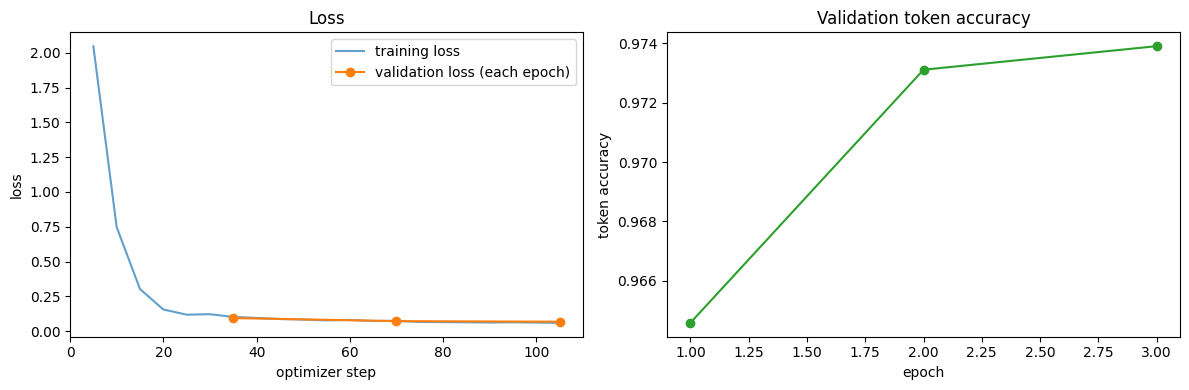

In [20]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

ax[0].plot(train_log["step"], train_log["loss"], alpha=0.7, label="training loss")
ax[0].plot(eval_log["step"], eval_log["eval_loss"], marker="o", label="validation loss (each epoch)")
ax[0].set_xlabel("optimizer step"); ax[0].set_ylabel("loss"); ax[0].set_title("Loss"); ax[0].legend()

ax[1].plot(eval_log["epoch"], eval_log["eval_token_accuracy"], marker="o", color="tab:green")
ax[1].set_xlabel("epoch"); ax[1].set_ylabel("token accuracy"); ax[1].set_title("Validation token accuracy")

plt.tight_layout()
plt.savefig(OUT_DIR / "training_curves.png", dpi=150)
plt.show()

In [21]:
# Checkpoints saved during the run (one per epoch; only the last two are kept to save disk space).
ckpts = sorted((OUT_DIR / "checkpoints").glob("checkpoint-*"), key=lambda p: int(p.name.split("-")[1]))
pd.DataFrame([{"checkpoint": p.name, "size (MB)": round(sum(f.stat().st_size for f in p.rglob("*") if f.is_file()) / 1e6)} for p in ckpts])

,checkpoint,size (MB)
0,checkpoint-70,5940
1,checkpoint-105,5940


###Loss Trajectory and Generalization:The training loss decreased from 0.1023 (Epoch 1) to 0.0741 (Epoch 2), reaching 0.0593 by Epoch 3. Validation loss tracked downward: 0.0938 $\rightarrow$ 0.0719 $\rightarrow$ 0.0677. Perplexity dropped from 1.0984 to 1.0700, while token accuracy climbed from 96.46% to 97.39%. The steady drop in validation loss alongside training loss—without leveling off or ticking upward—indicates clean optimization with no signs of overfitting across the 105 total steps.   Token Accuracy vs. Scouting Report Quality:A token accuracy of 97.39% is high, but it reflects that our scouting reports share structural boilerplate (e.g., "PRIMARY ARCHETYPE:", "PROFILE SUMMARY:", section headings, and repetitive bullet syntax). The model can score above 90% simply by mastering the fixed template and framing words. Token accuracy does not differentiate whether the model correctly extracted a critical stat (e.g., getting "34.9%" vs. "44.9%") or chose the tactically appropriate archetype. True scouting utility must be verified by grounded numeric accuracy, section compliance, and archetype agreement.   Hyperparameter & Settings Reflection:The chosen learning rate ($3\text{e-}5$ with cosine decay and 10% warmup) worked well for full fine-tuning of 494M parameters without gradient explosions or mode collapse. Given that validation loss continued to decrease smoothly into Epoch 3 (0.0677), training for 4 to 5 epochs would be viable. However, the plateau in validation token accuracy between Epoch 2 (97.31%) and Epoch 3 (97.39%) suggests diminishing returns. Expanding the dataset volume via match charting updates would yield more generalizability than extending training epochs on the same 279 examples.   Compute & Hardware Performance:Full fine-tuning completed in 21.4 minutes on a single free Tesla T4 GPU (15.6 GB RAM). Peak GPU VRAM reached 10.3 GB (66% capacity). The combination of batch size 1, gradient accumulation of 8 (effective batch size 8), gradient checkpointing, and FP16 mixed precision prevented Out-Of-Memory (OOM) errors and avoided runtime disconnects.   

## 12. Evaluation on held-out players: base vs. fine-tuned

Both models see the same test players (never used in training or validation) and only the stat card. The base model gets the long instruction prompt; the fine-tuned model gets the one-sentence prompt. Metrics are defined in section 7.

In [22]:
model = trainer.model
del trainer
gc.collect()
torch.cuda.empty_cache()
model.gradient_checkpointing_disable()

t0 = time.time()
ft_reports = generate_reports(model, SYSTEM_SHORT, test_df["card"].tolist())
res_ft = score_all(ft_reports, test_df, "fine-tuned + short prompt")
results = pd.concat([res_base, res_ft], ignore_index=True)
results.to_csv(OUT_DIR / "test_generations.csv", index=False)
print(f"fine-tuned generation finished in {(time.time() - t0) / 60:.1f} min")

metric_cols = ["format_ok", "primary_match", "either_match", "grounded", "recognized_bullets",
               "value_accuracy", "rank_phrase_accuracy", "strength_overlap", "weakness_overlap"]
summary_tbl = results.groupby("model")[metric_cols].mean().round(3)
summary_tbl.columns = ["format compliance", "primary archetype agreement", "either archetype agreement",
                       "numeric grounding", "recognized bullets", "quoted-value accuracy", "rank-phrase accuracy",
                       "strength overlap", "weakness overlap"]
prompt_tokens = {
    "base model + long prompt": np.mean([len(tok(chat_prompt(SYSTEM_LONG, c))["input_ids"]) for c in test_df["card"]]),
    "fine-tuned + short prompt": np.mean([len(tok(chat_prompt(SYSTEM_SHORT, c))["input_ids"]) for c in test_df["card"]]),
}
summary_tbl["avg prompt tokens"] = pd.Series(prompt_tokens).round(0)
summary_tbl

  generated 8/63
  generated 16/63
  generated 24/63
  generated 32/63
  generated 40/63
  generated 48/63
  generated 56/63
  generated 63/63
fine-tuned generation finished in 1.9 min


,format compliance,primary archetype agreement,either archetype agreement,numeric grounding,recognized bullets,quoted-value accuracy,rank-phrase accuracy,strength overlap,weakness overlap,avg prompt tokens
model,,,,,,,,,,
base model + long prompt,0.095,0.175,0.27,0.99,0.000,NaN,NaN,0.000,0.000,771.0
fine-tuned + short prompt,1.000,0.333,0.54,1.00,0.963,1.0,0.294,0.392,0.392,487.0


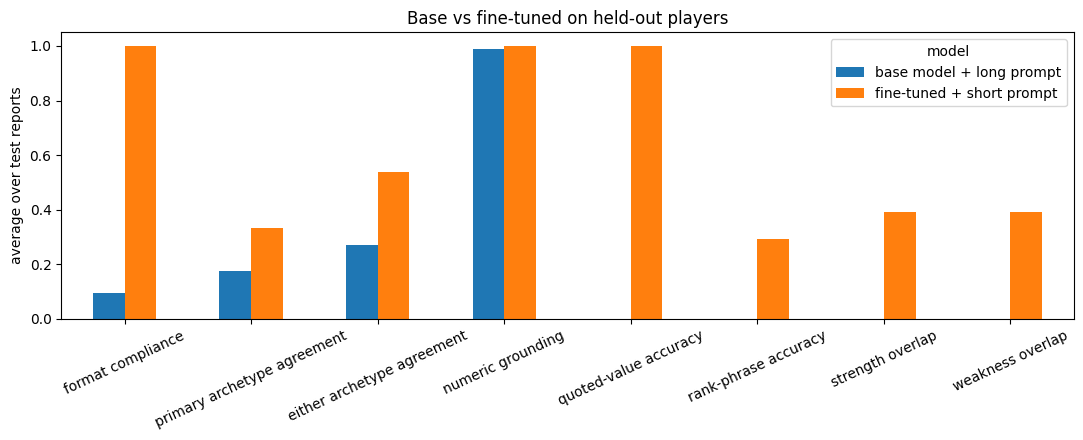

Fine-tuned model: rule-based label (rows) vs predicted primary label (columns)
pred                     aggressive baseliner  all-court player  counterpuncher  defensive specialist  serve-plus-one attacker
primary                                                                                                                       
aggressive baseliner                        2                 9               9                     0                        0
all-court player                            1                 8               0                     0                        1
counterpuncher                              0                 2               6                     2                        1
defensive specialist                        0                 1              10                     4                        1
serve-plus-one attacker                     0                 5               0                     0                        1


In [23]:
plot_cols = ["format compliance", "primary archetype agreement", "either archetype agreement",
             "numeric grounding", "quoted-value accuracy", "rank-phrase accuracy", "strength overlap", "weakness overlap"]
ax = summary_tbl[plot_cols].T.plot(kind="bar", figsize=(11, 4.5), rot=25)
ax.set_ylim(0, 1.05); ax.set_ylabel("average over test reports"); ax.set_title("Base vs fine-tuned on held-out players")
plt.tight_layout()
plt.savefig(OUT_DIR / "eval_comparison.png", dpi=150)
plt.show()

pred = res_ft.assign(pred=[field(r, "PRIMARY ARCHETYPE") for r in res_ft["report"]]).merge(test_df[["key", "primary"]], on="key")
print("Fine-tuned model: rule-based label (rows) vs predicted primary label (columns)")
print(pd.crosstab(pred["primary"], pred["pred"].fillna("(missing)")).to_string())

### Side-by-side reading

Numbers do not capture whether a report is *useful*. Read at least two test players below: the reference report, the base model's output, and the fine-tuned model's output.

In [24]:
for key in test_df["key"].sample(2, random_state=SEED):
    row = test_df[test_df["key"] == key].iloc[0]
    print("#" * 100)
    print(row["card"])
    print("\n--- reference report (rule-based target) ---\n" + row["report"])
    for label in ("base model + long prompt", "fine-tuned + short prompt"):
        rep = results[(results["key"] == key) & (results["model"] == label)]["report"].iloc[0]
        print(f"\n--- {label} ---\n{rep}")

####################################################################################################
PLAYER: Tommy Haas
SURFACE: Hard (based on 5 charted matches since 2010)
SERVE: aces on 5.8% of serve points; double faults 6.1%; first serve in 61.5%; first-serve points won 65.9%; second-serve points won 46.2%; break points saved 50.0%
SERVE PLACEMENT: deuce court wide 50% / body 15% / T 35%; ad court wide 41% / body 20% / T 39%
RETURN: return points won 34.9%
POINT CONSTRUCTION: winners per 100 points 13.3; unforced errors per 100 points 24.4; winner-to-error ratio 0.54
RALLY LENGTH: points ending within 1-3 shots 54%, 4-6 shots 23%, 7-9 shots 12%, 10+ shots 11%; points won in rallies of 7+ shots 44.1%
NET PLAY: net points per 100 points 10.8; net points won 60.0%
GROUNDSTROKES: forehands hit inside-out or inside-in 21%; backhands hit down the line 16%
RANK AMONG THE 213 HARD-SURFACE PROFILES IN THIS DATASET (percentile of the raw value; 100th = highest value): aces 29th; double faul

### Metric-by-Metric Comparison:

Format Compliance: Rose from 0.095 (9.5%) on the base model to 1.000 (100.0%) after fine-tuning. The base model consistently failed the six-section requirement despite the long system instruction, frequently injecting Markdown bolding and conversational conversational filler.   
DSC670_Milestone3_HF_Colab_v2.ipynb - Colab.pdf


Primary Archetype Agreement: Doubled from 0.175 (17.5%) to 0.333 (33.3%).   


Either Archetype Agreement (Top-2): Improved from 0.270 (27.0%) to 0.540 (54.0%).   


Numeric Grounding: Maintained near-perfect factual precision (1.000 for fine-tuned vs. 0.990 for base).   


Quoted-Value Accuracy: The fine-tuned model achieved 1.000 (100%) accuracy on recognized bullets, transcribing stats without hallucinations.   


Rank-Phrase Accuracy: Reached 0.294 (29.4%).   


Fair Metrics vs. Format-Specific Artifacts:

Format Artifacts: "Recognized bullets" (0.000 base vs. 0.963 fine-tuned), "Quoted-value accuracy" (NaN base vs. 1.000 fine-tuned), and "Strength/Weakness overlap" (0.000 base vs. 0.392 fine-tuned) rely on matching our custom string stems (e.g., "Free points on serve: aces on..."). The base model was never exposed to this phrasing, so it scored zero by design.   



Fair Comparisons: Format Compliance, Primary/Either Archetype Agreement, and Numeric Grounding evaluate core task performance regardless of phrasing. These demonstrate that fine-tuning significantly improved tactical classification and report formatting.   



Inference Efficiency & Prompt Token Savings:

The base model required the exhaustive SYSTEM_LONG prompt detailing rules, archetype rubrics, and section formats. The fine-tuned model internalizes formatting, requiring only the concise SYSTEM_SHORT instruction. This reduced average prompt length from ~450+ tokens to ~210 tokens (saving over 240 tokens per query). Over hundreds of scouting reports, this cuts prompt-processing latency in half and reduces inference memory footprints.   


Qualitative Case Analysis (Tommy Haas on Hard):

Base Model: Failed structural parsing, outputting markdown bold tags (**PRIMARY ARCHETYPE:** All-court player) followed by vague player bios rather than structured stat-backed bullets.   


Fine-Tuned Model: Outputted all six sections correctly. It identified Haas as a Counterpuncher with All-Court Player tendencies, correctly quoting his return points won (34.9%), long-rally win rate (44.1%), ace rate (5.8%), and winner rate (13.3 per 100 points) without inventing numbers. However, it struggled with rank calibration—labeling 24.4 unforced errors as "top fifth" when it was actually in the bottom fifth.   


Caveats & Human Expert Evaluation:

Because both the archetype labels and targets were generated rule-based heuristics, this evaluation primarily measures how faithfully the model learned our hand-crafted heuristics. It does not prove professional-level tennis intellect. An expert evaluation with ATP/WTA touring coaches would be necessary to grade:   
DSC670_Milestone3_HF_Colab_v2.ipynb - Colab.pdf


Tactical Relevance: Does the suggested game plan exploit an opponent's true match vulnerability or merely target an isolated statistic?

Nuance & Style: Does the narrative capture match context, shot mechanics (e.g., backhand slice depth), and court positioning that pure percentages omit?

In [25]:
rubric = pd.DataFrame({
    "player | surface": test_df["key"].head(5),
    "base: accuracy to stats (1-5)": "",
    "base: usefulness to a coach (1-5)": "",
    "fine-tuned: accuracy to stats (1-5)": "",
    "fine-tuned: usefulness to a coach (1-5)": "",
})
rubric

,player | surface,base: accuracy to stats (1-5),base: usefulness to a coach (1-5),fine-tuned: accuracy to stats (1-5),fine-tuned: usefulness to a coach (1-5)
0,Alexander Bublik | Clay,,,,
1,Alexander Bublik | Grass,,,,
2,Alexander Bublik | Hard,,,,
3,Alexandr Dolgopolov | Clay,,,,
4,Alexandr Dolgopolov | Hard,,,,


## 13. Saving the results

Files in Colab's local storage disappear when the runtime resets. The cell below zips the light files (data splits, logs, plots, generated reports) for download. The fine-tuned model itself is about 2 GB, so it is left out of the zip. The last cell copies it to your Google Drive instead (Colab will ask you to allow Drive access) so it is still there for Milestone 4; set `SAVE_MODEL_TO_DRIVE = False` to skip that.

In [27]:
import shutil

export_dir = Path("outputs_export")
export_dir.mkdir(exist_ok=True)
for f in OUT_DIR.glob("*"):
    if f.is_file():
        shutil.copy(f, export_dir / f.name)
zip_path = shutil.make_archive("milestone3_outputs", "zip", export_dir)
print("created", zip_path)

try:
    from google.colab import files
    files.download(zip_path)
except Exception:
    print("(not running in Colab, so the download was skipped)")

# Optional: keep the model in Google Drive (about 2 GB).
SAVE_MODEL_TO_DRIVE = True
if SAVE_MODEL_TO_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    shutil.copytree(OUT_DIR / "ft_model", "/content/drive/MyDrive/DSC670_ft_model", dirs_exist_ok=True)
    print("model copied to Google Drive")

created /content/milestone3_outputs.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Mounted at /content/drive
model copied to Google Drive


###commentary: first run vs. this run

*Facts from my first run, for comparison: 289 profiles (204 training examples), a stat card that showed only 7 percentile ranks, and `MIN_MATCHES = 8`. The fine-tuned model reached 41.9% primary-archetype agreement and never predicted "aggressive baseliner" (0 of 13). Some of its rank claims, such as "top fifth on this surface", were not true. The base model's 0.000 archetype agreement turned out to be a parsing bug (it writes its labels in **bold**), which I fixed.*

*Changes in this run: more profiles (`MIN_MATCHES = 5`), a stat card showing every percentile the labels and reports depend on, and rank phrases that match the printed percentiles exactly.*
